In [ ]:
import os
import sys

# Run from the project root so `src` imports and relative data paths resolve.
if os.path.basename(os.getcwd()) == "jupyter_notebooks":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

# Ornstein–Uhlenbeck trajectories

This notebook imports the local simulator, generates 10 sample paths, and visualizes them.

In [1]:
import matplotlib.pyplot as plt
import torch
from src.neural_variational_ode import Dissipation, Energy, VariationalODESolver
from src.ou_trajectories import generate_ou_trajectories
from src.xi_sigma import compute_xi_and_sigma
import numpy as np

In [637]:
params = {'font.family': 'serif',
          'font.sans-serif': 'Times New Roman',
          'font.size': 14,
          'lines.linewidth': 2,
          'text.usetex': False,
          'xtick.top': True,
          'xtick.minor.visible': True,
          'ytick.minor.visible': True,
          'xtick.direction': 'in',
          'xtick.major.top': True,
          'xtick.major.bottom': True,
          'xtick.minor.top': True,
          'xtick.minor.bottom': True,
          'xtick.minor.width': 1,
          'xtick.major.width': 1,
          'xtick.minor.size': 3, 
          'xtick.major.size': 6,
          'ytick.right': True,
          'ytick.direction': 'in',
          'ytick.major.left': True,
          'ytick.major.right': True,
          'ytick.minor.left': True,
          'ytick.minor.right': True,
          'ytick.minor.width': 1,
          'ytick.major.width': 1,
          'ytick.minor.size': 3,
          'ytick.major.size': 6,
          'legend.frameon': False,
          'lines.markersize': 4.0,
          'axes.formatter.use_mathtext': True,
          'text.latex.preamble' : r'\usepackage{amsmath}',
          'text.usetex': True}
plt.rcParams.update(params)

In [642]:
# SDE: dX_t = theta * (mu - X_t) dt + sigma * dW_t
theta = 10.0
mu = 1.0
sigma = 1
x0 = 0.0

# theta = np.asarray([[2.0, 0], [0, 2.0]])
# mu = np.asarray([1.0, 1.0])
# sigma = np.asarray([[0.3, 0], [0, 0.3]])
# x0 = np.asarray([0.0, 0.0])

times, paths = generate_ou_trajectories(
    theta=theta,
    mu=mu,
    sigma=sigma,
    x0=x0,
    n_trajectories=2,
    seed=torch.randint(0, 10000, (1,))[0].item(),
    T=10.0,
    dt=0.01,
)

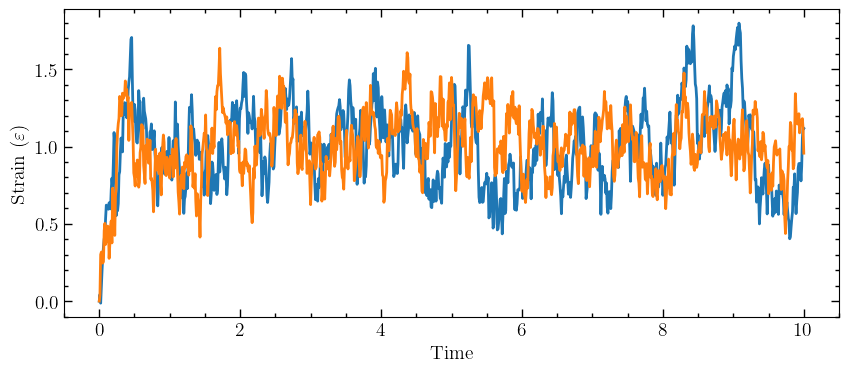

In [ ]:
plt.figure(figsize=(10, 4))
plt.plot(times, paths.T)
# plt.plot(times, paths[0])
plt.xlabel('Time')
plt.ylabel(r'Strain ($\varepsilon$)')
# plt.savefig('figs/oned-strain-samples.pdf')
plt.show()

In [647]:
# Use each OU trajectory as an input trajectory e(t).
xi, sigma_from_ou = compute_xi_and_sigma(paths, dt=times[1] - times[0])
print(f'xi shape: {xi.shape}')
print(f'sigma shape: {sigma_from_ou.shape}')

xi shape: (2, 1001)
sigma shape: (2, 1001)


In [625]:
1/(20*12)

0.004166666666666667

In [634]:
((xi - xi.mean(axis=0))* (paths - paths.mean(axis=0))).mean()

0.004029474474677603

In [555]:
# Load the neural W/D model saved by train_neural_variational_ode.py.
solver = VariationalODESolver(Energy(1, 1), Dissipation(1))
solver.load_state_dict(torch.load('neural_variational_ode_1.pt', map_location='cpu', weights_only=True))
solver.eval()

# Autograd remains enabled because the solver evaluates partial derivatives of W and D.
with torch.enable_grad():
    xi_predicted, sigma_predicted = solver.solve(
        torch.as_tensor(paths, dtype=torch.float32),
        dt=float(times[1] - times[0]),
        create_graph=False,
    )

xi_predicted = xi_predicted.detach().numpy()
sigma_predicted = sigma_predicted.detach().numpy()
xi_predicted.shape, sigma_predicted.shape

((200, 301), (200, 301))

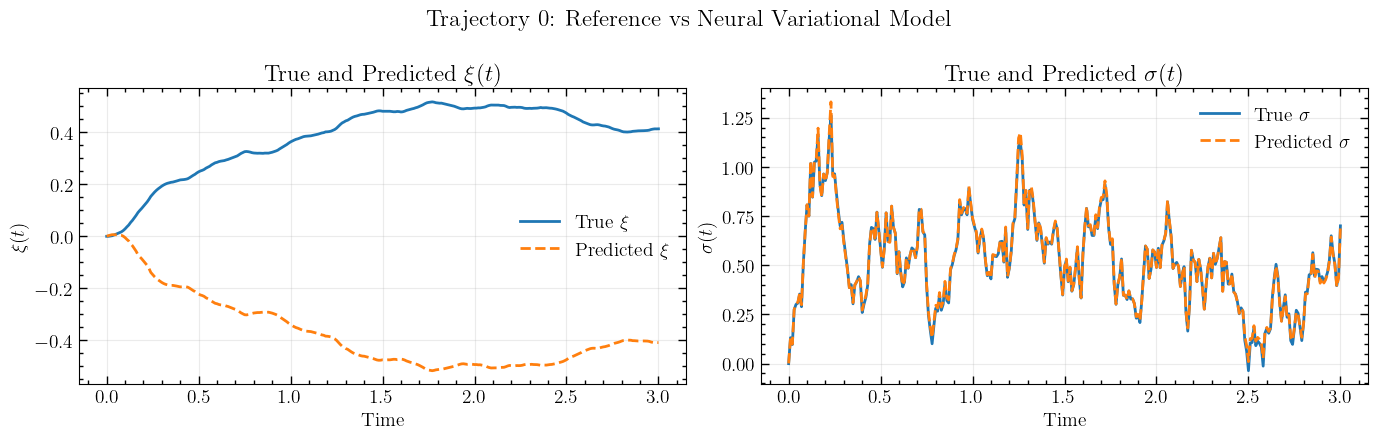

In [445]:
trajectory_index = 0
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)

axes[0].plot(times, xi[trajectory_index], label='True $\\xi$', linewidth=2)
axes[0].plot(times, xi_predicted[trajectory_index], '--', label='Predicted $\\xi$', linewidth=2)
axes[0].set(title='True and Predicted $\\xi(t)$', xlabel='Time', ylabel='$\\xi(t)$')

axes[1].plot(times, sigma_from_ou[trajectory_index], label='True $\\sigma$', linewidth=2)
axes[1].plot(times, sigma_predicted[trajectory_index], '--', label='Predicted $\\sigma$', linewidth=2)
axes[1].set(title='True and Predicted $\\sigma(t)$', xlabel='Time', ylabel='$\\sigma(t)$')

for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle(f'Trajectory {trajectory_index}: Reference vs Neural Variational Model')
fig.tight_layout()
plt.show()

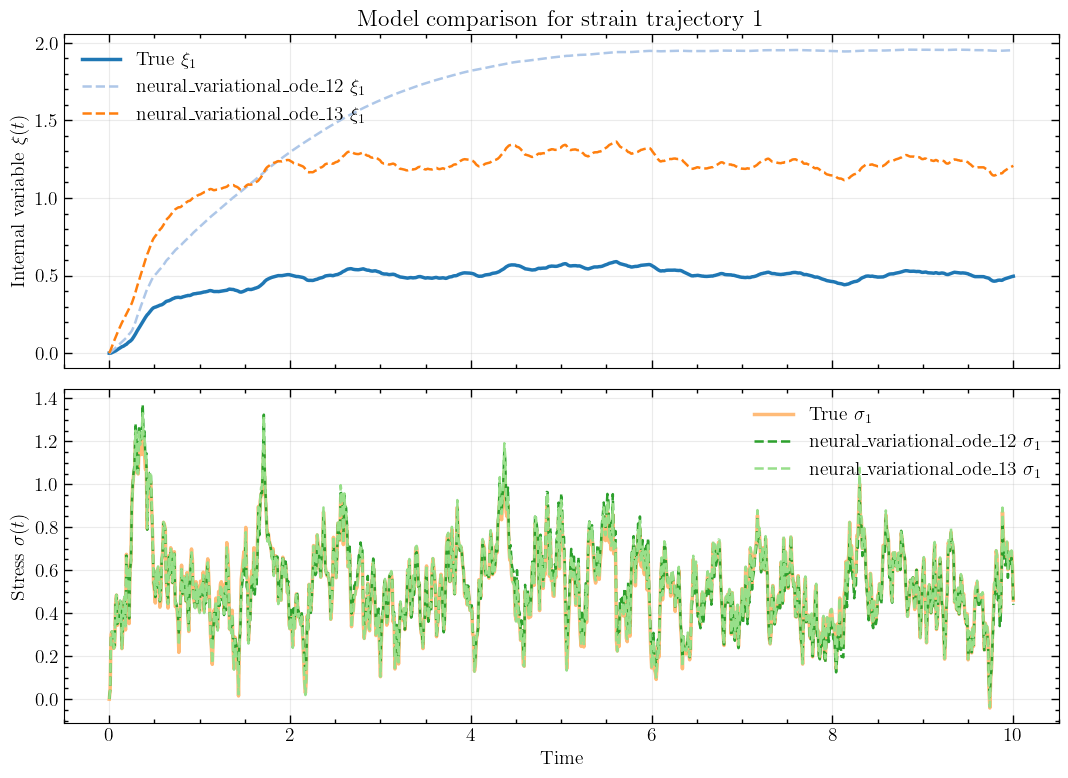

Compared 2 models: neural_variational_ode_12, neural_variational_ode_13


In [655]:
from pathlib import Path
import re

# Compare every saved neural variational ODE model on the same strain input.
model_paths = sorted(
    Path('.').glob('neural_variational_ode*.pt'),
    key=lambda path: [int(part) if part.isdigit() else part for part in re.split(r'(\d+)', path.name)],
)
if not model_paths:
    raise FileNotFoundError('No neural_variational_ode*.pt model files were found.')

# Use one existing OU strain trajectory so every model sees exactly the same input.
comparison_index = 1
strain_input = torch.as_tensor(
    paths[comparison_index:comparison_index + 1], dtype=torch.float32
)
dt_input = float(times[1] - times[0])

predictions = {}
for model_path in model_paths:
    model_solver = VariationalODESolver(Energy(1, 1), Dissipation(1))
    model_solver.load_state_dict(
        torch.load(model_path, map_location='cpu', weights_only=True)
    )
    model_solver.eval()
    with torch.enable_grad():
        xi_model, stress_model = model_solver.solve(
            strain_input, dt=dt_input, create_graph=False
        )
    predictions[model_path.stem] = {
        'xi': xi_model.detach().cpu().numpy()[0],
        'stress': stress_model.detach().cpu().numpy()[0],
    }

true_xi = np.asarray(xi[comparison_index])
true_stress = np.asarray(sigma_from_ou[comparison_index])
if true_xi.ndim == 1:
    true_xi = true_xi[:, np.newaxis]
if true_stress.ndim == 1:
    true_stress = true_stress[:, np.newaxis]

n_xi_components = true_xi.shape[-1]
n_stress_components = true_stress.shape[-1]
n_total_lines = (
    n_xi_components * (1 + len(predictions))
    + n_stress_components * (1 + len(predictions))
)
palette = np.asarray(plt.get_cmap('tab20').colors)
if n_total_lines > len(palette):
    raise ValueError(
        f'tab20 provides {len(palette)} distinct colors, but '
        f'{n_total_lines} lines are required.'
    )
line_colors = palette[:n_total_lines]
line_index = 0

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for component_index in range(n_xi_components):
    color = line_colors[line_index]
    line_index += 1
    axes[0].plot(
        times,
        true_xi[:, component_index],
        color=color,
        linestyle='-',
        linewidth=2.5,
        label=f'True $\\xi_{component_index + 1}$',
    )
    for model_name, output in predictions.items():
        predicted_xi = np.asarray(output['xi'])
        if predicted_xi.ndim == 1:
            predicted_xi = predicted_xi[:, np.newaxis]
        color = line_colors[line_index]
        line_index += 1
        axes[0].plot(
            times,
            predicted_xi[:, component_index],
            color=color,
            linestyle='--',
            linewidth=1.8,
            label=f'{model_name} $\\xi_{component_index + 1}$',
        )

for component_index in range(n_stress_components):
    color = line_colors[line_index]
    line_index += 1
    axes[1].plot(
        times,
        true_stress[:, component_index],
        color=color,
        linestyle='-',
        linewidth=2.5,
        label=f'True $\\sigma_{component_index + 1}$',
    )
    for model_name, output in predictions.items():
        predicted_stress = np.asarray(output['stress'])
        if predicted_stress.ndim == 1:
            predicted_stress = predicted_stress[:, np.newaxis]
        color = line_colors[line_index]
        line_index += 1
        axes[1].plot(
            times,
            predicted_stress[:, component_index],
            color=color,
            linestyle='--',
            linewidth=1.8,
            label=f'{model_name} $\\sigma_{component_index + 1}$',
        )

axes[0].set_ylabel('Internal variable $\\xi(t)$')
axes[0].set_title(f'Model comparison for strain trajectory {comparison_index}')
axes[1].set_ylabel('Stress $\\sigma(t)$')
axes[1].set_xlabel('Time')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
# plt.savefig('figs/internal_variable_comparison_covariance_regularization.pdf')
plt.show()

print(f'Compared {len(predictions)} models: {", ".join(predictions)}')

In [12]:
results = np.load("neural_bar_results.npz")

In [21]:
results.keys()

KeysView(NpzFile 'neural_bar_results.npz' with keys: x, load, displacement, strain, stress)

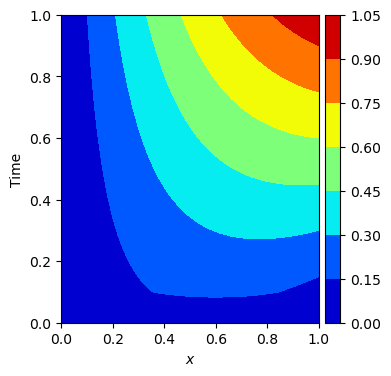

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4))
x = np.linspace(0, 1, results['displacement'].shape[1])
y = np.linspace(0, 1, results['load'].shape[0])
X, Y = np.meshgrid(x, y)

im = ax.contourf(X, Y, results['displacement'], cmap='jet')
plt.xlabel('$x$')
plt.ylabel('Time')

cbar = fig.colorbar(im, ax=ax, pad=0.02, shrink=1.0)

plt.show()

In [91]:
class TrueConstitutiveLaw:
    """Evaluate the analytical linear constitutive relation on strain paths."""

    def __init__(self, node_count: int, model_dt: float, p: float = 1.0) -> None:
        if node_count < 1:
            raise ValueError("node_count must be positive.")
        if model_dt <= 0:
            raise ValueError("model_dt must be positive.")
        self.node_count = node_count
        self.model_dt = model_dt
        self.p = p

    def stress_history(self, strain_history: np.ndarray) -> np.ndarray:
        """Return stress for every time and node in a strain history.

        Parameters
        ----------
        strain_history : numpy.ndarray, shape (time, node)
            Strain values sampled at uniform model time steps.
        """
        strain = np.asarray(strain_history, dtype=float)
        if strain.ndim != 2 or strain.shape[1] != self.node_count:
            raise ValueError("strain_history must have shape (time, node_count).")
        if strain.shape[0] == 0:
            raise ValueError("strain_history must contain at least one time point.")

        internal_variable = np.zeros_like(strain)
        for time_index in range(strain.shape[0] - 1):
            if self.p > 0:
                internal_variable[time_index + 1] = (
                    internal_variable[time_index]
                    + self.model_dt
                    * np.power(2*np.abs(strain[time_index] - 1.0 * internal_variable[time_index]), 1.0/self.p)
                    * np.sign(strain[time_index] - 1.0 * internal_variable[time_index])
                )
        return internal_variable, strain - internal_variable

    def stress(self, strain_history: np.ndarray) -> np.ndarray:
        """Return the final stress state for the FEM residual."""
        return self.stress_history(strain_history)[-1]

In [92]:
T = 1
n_steps = 1000
dt = T / n_steps
tcl = TrueConstitutiveLaw(node_count=1, model_dt=dt, p=0.01)
time = np.linspace(0, T, n_steps+1) 
max_strain = 2
tensile_load = np.linspace(0, max_strain, n_steps+1).reshape(-1, 1)
tensile_unload = np.linspace(max_strain, 0, n_steps+1).reshape(-1, 1)
compression_load = np.linspace(0, -max_strain, n_steps+1).reshape(-1, 1)
compression_unload = np.linspace(-max_strain, 0, n_steps+1).reshape(-1, 1)
load_cycle = np.vstack((tensile_load, tensile_unload, compression_load, compression_unload))

strain_history = np.vstack((load_cycle, tensile_load))
iv_history, stress_history = tcl.stress_history(strain_history)
stress_parts = np.split(stress_history, 5)
iv_parts = np.split(iv_history, 5)

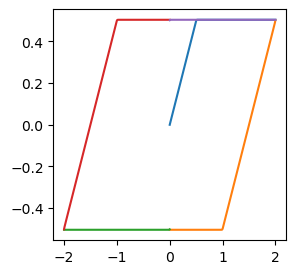

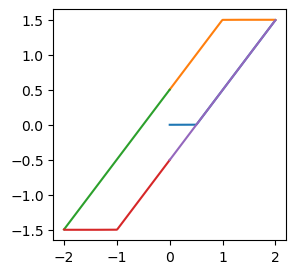

In [93]:

plt.figure(figsize=(3,3))
plt.plot(tensile_load, stress_parts[0])
plt.plot(tensile_unload, stress_parts[1])
plt.plot(compression_load, stress_parts[2])
plt.plot(compression_unload, stress_parts[3])
plt.plot(tensile_load, stress_parts[4])
plt.show()

plt.figure(figsize=(3,3))
plt.plot(tensile_load, iv_parts[0])
plt.plot(tensile_unload, iv_parts[1])
plt.plot(compression_load, iv_parts[2])
plt.plot(compression_unload, iv_parts[3])
plt.plot(tensile_load, iv_parts[4])
plt.show()

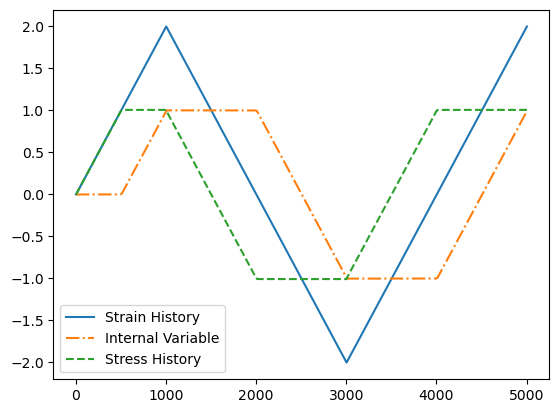

In [84]:
plt.plot(strain_history, '-', label='Strain History')
plt.plot(iv_history, '-.', label='Internal Variable')
plt.plot(stress_history, '--', label='Stress History')
plt.legend()

In [206]:
class IsotropicHardeningPlasticity:
    """One-dimensional plasticity with isotropic hardening.

    The model is

        stress = strain - xi,
        xi_dot = |stress / yield_stress|**(1 / p) sign(stress),
        yield_stress_dot = H * |xi_dot|.

    For ``p > 0`` the equations are integrated with forward Euler. For
    ``p == 0`` the rate-independent response is computed with a 1D return map.
    """

    def __init__(
        self,
        node_count: int,
        model_dt: float,
        sigma0: float = 0.1,
        hardening_modulus: float = 0.0,
        p: float = 1.0,
    ) -> None:
        if node_count < 1:
            raise ValueError("node_count must be positive.")
        if model_dt <= 0:
            raise ValueError("model_dt must be positive.")
        if sigma0 <= 0:
            raise ValueError("sigma0 must be positive.")
        if hardening_modulus < 0:
            raise ValueError("hardening_modulus must be non-negative.")
        if p < 0:
            raise ValueError("p must be non-negative.")
        self.node_count = node_count
        self.model_dt = model_dt
        self.sigma0 = sigma0
        self.hardening_modulus = hardening_modulus
        self.p = p

    def stress_history(self, strain_history: np.ndarray) -> np.ndarray:
        """Return stress for every time and node in a strain history."""
        strain = np.asarray(strain_history, dtype=float)
        if strain.ndim != 2 or strain.shape[1] != self.node_count:
            raise ValueError("strain_history must have shape (time, node_count).")
        if strain.shape[0] == 0:
            raise ValueError("strain_history must contain at least one time point.")

        internal_variable = np.zeros(self.node_count, dtype=float)
        yield_stress = np.full(self.node_count, self.sigma0, dtype=float)
        stress = np.empty_like(strain)
        stress[0] = strain[0] - internal_variable

        for time_index in range(strain.shape[0] - 1):
            trial_stress = strain[time_index + 1] - internal_variable
            if self.p == 0:
                overstress = np.maximum(
                    np.abs(trial_stress) - yield_stress, 0.0
                )
                plastic_increment = (
                    np.sign(trial_stress)
                    * overstress
                    / (1.0 + self.hardening_modulus)
                )
                internal_variable += plastic_increment
                yield_stress += self.hardening_modulus * np.abs(plastic_increment)
            else:
                rate = (
                    np.abs(trial_stress / yield_stress) ** (1.0 / self.p)
                    * np.sign(trial_stress)
                )
                internal_variable += self.model_dt * rate
                yield_stress += self.hardening_modulus * self.model_dt * np.abs(rate)
            stress[time_index + 1] = strain[time_index + 1] - internal_variable

        return stress

    def stress(self, strain_history: np.ndarray) -> np.ndarray:
        """Return the final stress state for the FEM residual."""
        return self.stress_history(strain_history)[-1]

class HardeningPlasticity:
    """One-dimensional plasticity with isotropic hardening.

    The model is

        stress = strain - xi,
        xi_dot = |stress / yield_stress|**(1 / p) sign(stress),
        yield_stress_dot = H * |xi_dot|.

    For ``p > 0`` the equations are integrated with forward Euler. For
    ``p == 0`` the rate-independent response is computed with a 1D return map.
    """

    def __init__(
        self,
        node_count: int,
        model_dt: float,
        sigma0: float = 0.1,
        H: float = 1.0,
        E: float = 1.0,
        p: float = 1.0,
    ) -> None:
        if node_count < 1:
            raise ValueError("node_count must be positive.")
        if model_dt <= 0:
            raise ValueError("model_dt must be positive.")
        if sigma0 <= 0:
            raise ValueError("sigma0 must be positive.")
        if H < 0:
            raise ValueError("H must be non-negative.")
        if p < 0:
            raise ValueError("p must be non-negative.")
        self.node_count = node_count
        self.model_dt = model_dt
        self.sigma0 = sigma0
        self.H = H
        self.E = E
        self.p = p

    def stress_history(self, strain_history: np.ndarray) -> np.ndarray:
        """Return stress for every time and node in a strain history."""
        strain = np.asarray(strain_history, dtype=float)
        if strain.ndim != 2 or strain.shape[1] != self.node_count:
            raise ValueError("strain_history must have shape (time, node_count).")
        if strain.shape[0] == 0:
            raise ValueError("strain_history must contain at least one time point.")

        internal_variable = np.zeros(self.node_count, dtype=float)
        plastic_strain = np.zeros(self.node_count, dtype=float)
        stress = np.empty_like(strain)
        internal_variable_history = np.empty_like(strain)
        internal_variable_history[0] = internal_variable
        plastic_strain_history = np.empty_like(strain)
        plastic_strain_history[0] = plastic_strain
        stress[0] = strain[0] - internal_variable

        for time_index in range(strain.shape[0] - 1):
            elastic_increment = self.E*(strain[time_index + 1] - plastic_strain)
            plastic_correction = self.H*internal_variable
            denominator = self.H + self.E + 1/self.model_dt
            plastic_increment_pos = (elastic_increment - plastic_correction)/denominator
            plastic_increment_neg = (elastic_increment + plastic_correction)/denominator
            if plastic_increment_pos >= 0:
                plastic_increment = plastic_increment_pos
                # print(f"Plastic increment at time {time_index}: {plastic_increment}")
            elif plastic_increment_neg <= 0:
                plastic_increment = plastic_increment_neg
                # print(f"Plastic increment at time {time_index}: {plastic_increment}")
            else: 
                break
                raise ValueError("Plastic increment is undefined.")
            plastic_strain += plastic_increment
            internal_variable += np.abs(plastic_increment)
            # print(internal_variable)
            stress[time_index + 1] = strain[time_index + 1] -plastic_strain
            internal_variable_history[time_index + 1] = internal_variable
            plastic_strain_history[time_index + 1] = plastic_strain
        return stress, internal_variable_history, plastic_strain_history
        # Note: stress_history is not defined, so it should be removed from the return statement.
        return stress, internal_variable_history, plastic_strain_history

    def stress(self, strain_history: np.ndarray) -> np.ndarray:
        """Return the final stress state for the FEM residual."""
        return self.stress_history(strain_history)[-1]

In [207]:
T = 2
n_steps = 1000
dt = T / n_steps
time = np.linspace(0, T, n_steps+1) 
max_strain = 0.2
tensile_load = np.linspace(0, max_strain, n_steps+1).reshape(-1, 1)
tensile_unload = np.linspace(max_strain, 0, n_steps+1).reshape(-1, 1)
# compression_load = np.linspace(0, -max_strain, n_steps+1).reshape(-1, 1)
# compression_unload = np.linspace(-max_strain, 0, n_steps+1).reshape(-1, 1)
# load_cycle = np.vstack((tensile_load, tensile_unload, compression_load, compression_unload))

strain_history = np.vstack((tensile_load, tensile_unload, compression_load, compression_unload))
# stress_parts = np.split(stress_history, 5)
# iv_parts = np.split(iv_history, 5)

law = HardeningPlasticity(
    node_count=1,
    model_dt=dt,
    E=1.0,
    H=0.1,
)

stress_history, internal_variable_history, plastic_strain_history = law.stress_history(strain_history)

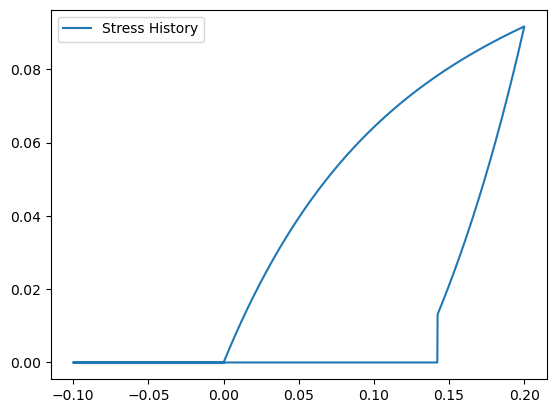

In [208]:
# plt.plot(strain_history, label='Strain History')
plt.plot(strain_history, stress_history, label='Stress History')
plt.legend()
# plt.plot(stress_history)

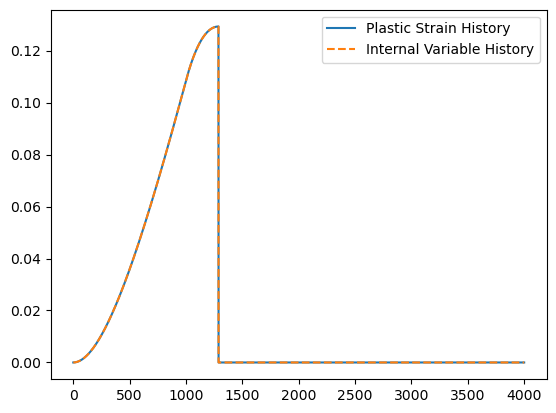

In [209]:
plt.plot(plastic_strain_history, label='Plastic Strain History')
plt.plot(internal_variable_history, '--', label='Internal Variable History')
plt.legend(
)

In [231]:
from true_constitutive_model import VariationalIsotropicHardeningPlasticity

model = VariationalIsotropicHardeningPlasticity(
    node_count=1,
    model_dt=0.01,
    elastic_modulus=1.0,
    hardening_modulus=0.05,
    dissipation_exponent=10.0,
)

stress_history = model.stress_history(strain_history)

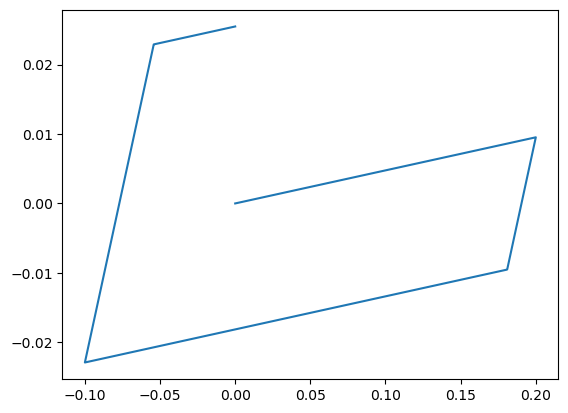

In [232]:
plt.plot(strain_history,stress_history)